# 06 · Tipo de rede, componente gigante, passeio aleatório e similaridade de cosseno

**Objetivo:** responder "que tipo de rede é a do Pix?" com as ferramentas certas e conhecer duas ideias que viram algoritmos de detecção: o passeio aleatório (que está por trás do PageRank) e a similaridade de cosseno (que compara contas pelos valores que movimentam).

**Conceitos:** distribuição de graus de entrada e de saída, lei de potência e seu expoente, modelo de Barabási–Albert (ligação preferencial), componente gigante (fraca e forte) e a transição de fase do Erdős–Rényi, passeio aleatório e matriz de transição, similaridade de cosseno e ângulo entre vetores.

**Leitura de apoio:** Barabási, *Network Science*, cap. 3 (redes aleatórias e componente gigante), 4 (leis de potência) e 5 (Barabási–Albert); Clauset, Shalizi e Newman (2009), *Power-law distributions in empirical data*; Easley & Kleinberg, cap. 14 (PageRank como passeio aleatório).

Pedido da [reunião de 24/09](../docs/reunioes/2026-09-24.md). As funções usadas aqui estão em `pixfraud.network` e `pixfraud.algorithms`.

In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

from pixfraud.algorithms import cosine_similarity, similar_accounts, vector_angle
from pixfraud.graph import build_graph, graph_from_edges
from pixfraud.network import (
    component_summary,
    compare_network_models,
    degree_sequence,
    fit_power_law,
    giant_component,
    random_walk,
    random_walk_visits,
)
from pixfraud.simulation import generate_dataset, load_config

contas, tx = generate_dataset(load_config("../configs/experimento.yaml"))
G = build_graph(tx, contas["account_id"])
papel = contas.set_index("account_id")["role"]
print(f"{G.number_of_nodes()} contas, {G.number_of_edges()} pares (pagador → recebedor)")

2142 contas, 32446 pares (pagador → recebedor)


## 1. Arestas direcionadas

No Pix o dinheiro tem sentido: a aresta $u \to v$ quer dizer "$u$ pagou $v$". Por isso o grafo do projeto é um `DiGraph`, e cada conta tem **dois** graus:

* grau de **entrada** $k^{\text{in}}$: de quantas contas distintas ela recebeu;
* grau de **saída** $k^{\text{out}}$: para quantas contas distintas ela pagou.

Numa rede não direcionada esses dois números se confundem num só. Aqui eles contam histórias diferentes: um comércio tem $k^{\text{in}}$ enorme e $k^{\text{out}} = 0$; uma coletora de quadrilha recebe de poucas laranjas e, no gerador padrão, paga pouca gente.

In [2]:
graus = pd.DataFrame({"entrada": dict(G.in_degree()), "saída": dict(G.out_degree())}).join(papel.rename("papel"))
graus.groupby("papel")[["entrada", "saída"]].agg(["mean", "max"]).round(1)

entrada       saída    
                 mean   max  mean max
papel                                
coletor           2.0     4   3.3   4
comercio        123.3  1573   0.0   0
intermediario     2.0     4   4.2   7
laranja           7.2    19   4.3   7
normal           10.0    19  16.1  52

## 2. Lei de potência

Uma distribuição de graus segue uma **lei de potência** quando

$$P(k) \propto k^{-\alpha}, \qquad k \geq k_{\min}.$$

Tirando o logaritmo, $\log P(k) = -\alpha \log k + c$: em escala log-log vira uma **reta** de inclinação $-\alpha$. A acumulada complementar $P(K \geq k) \propto k^{-(\alpha - 1)}$ também é uma reta, e é ela que se desenha, porque é bem menos ruidosa que o histograma.

Ajustar uma reta no gráfico log-log é o jeito **errado** de estimar $\alpha$: a regressão dá peso demais aos pontos ruidosos da cauda. O jeito certo (Clauset et al., 2009) é a máxima verossimilhança:

$$\hat\alpha = 1 + n \Big/ \sum_{i=1}^{n} \ln \frac{k_i}{k_{\min} - \tfrac12},$$

em que a soma percorre só os $n$ vértices da cauda ($k_i \geq k_{\min}$). O $k_{\min}$ é escolhido para minimizar a distância de Kolmogorov–Smirnov (KS) entre a cauda observada e a ajustada. É o que `fit_power_law` faz.

In [3]:
ajustes = pd.DataFrame({tipo: fit_power_law(degree_sequence(G, tipo)) for tipo in ("in", "out", "total")}).T
ajustes.round(3)

,alpha,k_min,ks,n_cauda,fracao_cauda
in,2.035,34.0,0.056,77.0,0.036
out,7.943,33.0,0.044,71.0,0.035
total,4.179,22.0,0.065,1250.0,0.584


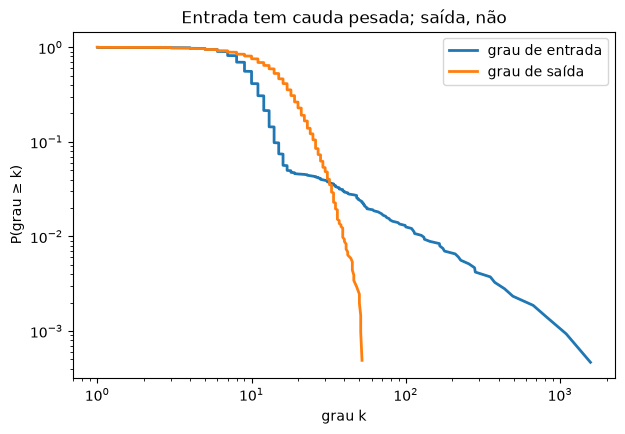

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for tipo, rotulo in (("in", "entrada"), ("out", "saída")):
    k = np.sort(degree_sequence(G, tipo))
    k = k[k > 0]
    ax.loglog(k, 1 - np.arange(len(k)) / len(k), lw=2, label=f"grau de {rotulo}")
ax.set_xlabel("grau k")
ax.set_ylabel("P(grau ≥ k)")
ax.legend()
ax.set_title("Entrada tem cauda pesada; saída, não");

**Interpretação.** A cauda do grau de **entrada** é aproximadamente reta, com $\alpha \approx 2$: é a popularidade dos comércios, que o gerador sorteia com uma lei de Zipf (poucos comércios recebem de quase todo mundo). O grau de **saída** cai depressa ($\alpha$ grande, KS pior): ninguém paga milhares de contas distintas. Então a rede Pix sintética **não** é uma rede livre de escala "pura". Ela tem hubs de recebimento, e só deles.

Para a fraude isso importa porque um atributo como "recebe de muita gente" é normal para um comércio e suspeito para uma pessoa física. O modelo nulo precisa respeitar essa assimetria.

## 3. Barabási–Albert: de onde vem a lei de potência

O modelo de Barabási–Albert (1999) gera redes com lei de potência a partir de duas regras:

1. **crescimento:** a rede começa pequena e ganha um vértice novo por passo;
2. **ligação preferencial:** o vértice novo se liga a $m$ vértices antigos, escolhendo o vértice $i$ com probabilidade $\Pi(k_i) = k_i / \sum_j k_j$. Quem já tem muitas ligações ganha mais ("os ricos ficam mais ricos").

O resultado é $P(k) \propto k^{-3}$ (ou seja, $\alpha = 3$), qualquer que seja $m$. Sem ligação preferencial (escolha uniforme) a cauda vira exponencial. Sem crescimento, a rede acaba completa.

In [5]:
for m in (1, 3, 10):
    ba = nx.barabasi_albert_graph(5000, m, seed=1)
    ajuste = fit_power_law(degree_sequence(ba))
    print(f"BA com m = {m:2d}: alpha = {ajuste['alpha']:.2f} (k_min = {ajuste['k_min']}, KS = {ajuste['ks']:.3f})")

BA com m =  1: alpha = 2.60 (k_min = 3, KS = 0.028)


BA com m =  3: alpha = 2.71 (k_min = 5, KS = 0.009)


BA com m = 10: alpha = 2.88 (k_min = 12, KS = 0.006)


Os expoentes ficam entre 2,6 e 2,9: perto de 3, um pouco abaixo porque a rede é finita e a convergência para 3 é lenta (os vértices mais antigos ainda não "descolaram" o suficiente).

Agora a rede Pix ao lado de um Erdős–Rényi e de um Barabási–Albert com o **mesmo número de vértices e arestas** (todos tratados como não direcionados):

In [6]:
compare_network_models(G, seed=1).round(3)

,vertices,arestas,grau_medio,grau_maximo,alpha,k_min,ks,agrupamento_medio,gigante,distancia_media
rede analisada,2142.0,29830.0,27.852,1573.0,4.179,22.0,0.065,0.254,1.0,2.249
Erdős–Rényi,2142.0,29830.0,27.852,48.0,14.991,36.0,0.028,0.013,1.0,2.676
Barabási–Albert,2142.0,29792.0,27.817,278.0,2.862,14.0,0.011,0.043,1.0,2.594


Leitura da tabela:

* **grau máximo:** o Erdős–Rényi quase não tem hubs (graus concentrados perto da média, distribuição de Poisson); o BA tem; a rede Pix tem hubs ainda maiores (os comércios mais populares);
* **$\alpha$:** o do Erdős–Rényi é enorme porque a cauda dele não é uma potência: o ajuste "força" uma reta numa curva que despenca;
* **agrupamento:** o da rede Pix é muito maior que o dos dois modelos, por causa dos círculos de contatos (a ideia do Watts–Strogatz, notebook 05);
* **distância média:** curta nos três ("mundo pequeno").

A rede Pix é uma **mistura**: cauda pesada nos recebimentos, como no BA, e agrupamento de comunidades, que nenhum dos dois modelos tem.

## 4. Componente gigante

Uma **componente conexa** é um grupo de vértices em que dá para ir de qualquer um a qualquer outro. Em grafos direcionados há dois tipos:

* **fraca:** ignorando o sentido das arestas;
* **forte:** respeitando o sentido. Dá para ir *e voltar* seguindo o dinheiro.

A **componente gigante** é a que contém uma fração **constante** dos vértices, mesmo quando a rede cresce. No Erdős–Rényi $G(n, p)$ ela aparece de repente, numa **transição de fase**, quando o grau médio $\langle k \rangle = p(n-1)$ passa de 1:

* $\langle k \rangle < 1$: só componentes pequenas, de tamanho $O(\log n)$;
* $\langle k \rangle > 1$: uma componente gigante com fração $S$ que resolve $S = 1 - e^{-\langle k \rangle S}$;
* $\langle k \rangle > \ln n$: quase certamente a rede inteira está conectada.

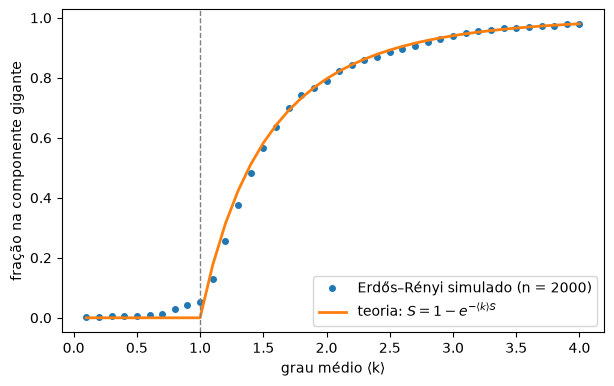

In [7]:
from scipy.optimize import brentq

n = 2000
medios = np.linspace(0.1, 4, 40)
simulado = [len(giant_component(nx.gnp_random_graph(n, k / (n - 1), seed=3))) / n for k in medios]
teoria = [brentq(lambda s: s - 1 + np.exp(-k * s), 1e-9, 1) if k > 1 else 0 for k in medios]

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(medios, simulado, "o", ms=4, label="Erdős–Rényi simulado (n = 2000)")
ax.plot(medios, teoria, lw=2, label=r"teoria: $S = 1 - e^{-\langle k \rangle S}$")
ax.axvline(1, color="gray", ls="--", lw=1)
ax.set_xlabel("grau médio ⟨k⟩")
ax.set_ylabel("fração na componente gigante")
ax.legend();

Na rede Pix o grau médio é dezenas de vezes maior que 1, então a componente gigante **fraca** tem praticamente todas as contas. A **forte** é o que distingue: quem só recebe e nunca paga (os comércios) não tem caminho de volta e fica fora dela. As contas de fraude ficam dentro, graças aos Pix de camuflagem.

In [8]:
print(component_summary(G).round(3).to_string())
forte = giant_component(G, strong=True)
fora = papel.drop(list(forte)).value_counts()
print("\nquem fica fora da componente gigante forte:")
print(fora.to_string())

vertices              2142.000
isolados                 0.000
componentes_fracas       1.000
gigante_fraca            1.000
componentes_fortes     107.000
gigante_forte            0.951

quem fica fora da componente gigante forte:
role
comercio    100
normal        6


## 5. Passeio aleatório

Um **passeio aleatório** anda pela rede escolhendo, a cada passo, uma das arestas que saem do vértice atual. Com pesos, a aresta $u \to v$ é escolhida com probabilidade

$$P_{uv} = \frac{w_{uv}}{\sum_{x} w_{ux}},$$

e $P$ é a **matriz de transição** ($P = D^{-1}A$, em que $D$ é a diagonal com a soma de cada linha de $A$). A distribuição de onde o passeio está depois de muitos passos é a **distribuição estacionária** $\pi = \pi P$. O **PageRank** é exatamente isso, com um "teletransporte" para uma conta sorteada com probabilidade $1 - \alpha$, que garante que $\pi$ exista e seja única (notebook 03). A propagação de risco (`flow.propagate_risk`) é o mesmo passeio, só que o teletransporte volta sempre para as fraudes conhecidas.

Aqui o peso é o valor: o passeio **segue o dinheiro**. Partindo de uma vítima, ele tende a ir pelo Pix do golpe (que é grande) até a laranja e daí pela cadeia de lavagem.

In [9]:
vitima = contas.loc[contas["is_victim"], "account_id"].iloc[0]
for semente in range(3):
    caminho = random_walk(G, vitima, max_steps=6, rng=semente)
    print(" → ".join(f"{c} ({papel[c]})" for c in caminho))

C000001 (normal) → C001987 (laranja) → C000555 (coletor) → C000432 (comercio)
C000001 (normal) → C001879 (normal) → C001987 (laranja) → C000555 (coletor) → C001905 (normal) → C001404 (normal) → C001024 (normal)
C000001 (normal) → C001879 (normal) → C000560 (comercio)


Um passeio sozinho é muito ruidoso. Com muitos passeios saindo de **todas** as vítimas, `random_walk_visits` mede que fração deles passa por cada conta:

In [10]:
vitimas = contas.loc[contas["is_victim"], "account_id"]
passeios = random_walk_visits(G, vitimas, walks_per_start=20, seed=0)
print(passeios.join(papel.rename("papel")).head(6).round(3).to_string())
# comparação justa: a média por conta de cada papel (há 2000 pessoas e poucas dezenas de contas de fraude)
por_papel = passeios.reindex(papel.index, fill_value=0.0).join(papel.rename("papel")).groupby("papel")
por_papel[["visitas", "destino"]].mean().sort_values("visitas", ascending=False).round(4)

         visitas  destino     papel
C001118    0.215    0.215  comercio
C000560    0.096    0.096  comercio
C001505    0.057    0.057  comercio
C000499    0.054    0.054  comercio
C000323    0.040    0.040  comercio
C002051    0.038    0.038  comercio


,visitas,destino
papel,,
intermediario,0.0352,0.00
coletor,0.0332,0.00
laranja,0.0100,0.00
comercio,0.0100,0.01
normal,0.0008,0.00


Os passeios **terminam** nos comércios: eles nunca pagam ninguém, então são sorvedouros e acumulam o fim de todos os passeios. Por conta, porém, as mais visitadas são as das quadrilhas: um intermediário ou uma coletora recebe dezenas de vezes mais visitas que uma pessoa comum. É a intuição da "culpa por associação" ([resultados, seção de propagação](../docs/resultados.md)): quem recebe o dinheiro que sai das vítimas é suspeito, mesmo sem nenhum atributo anômalo.

## 6. Similaridade de cosseno e ângulo entre vetores

Duas contas podem ser comparadas como **vetores**: a conta $a$ vira $a = (a_1, \dots, a_n)$, em que $a_i$ é quanto ela pagou para a conta $i$. A **similaridade de cosseno** é o cosseno do ângulo $\theta$ entre os dois vetores:

$$\cos\theta = \frac{a \cdot b}{\lVert a \rVert\, \lVert b \rVert} = \frac{\sum_i a_i b_i}{\sqrt{\sum_i a_i^2}\,\sqrt{\sum_i b_i^2}}.$$

A fórmula vem da definição geométrica do produto interno, $a \cdot b = \lVert a \rVert \lVert b \rVert \cos\theta$. Por isso **"similaridade de cosseno" e "ângulo entre vetores" são a mesma medida**, em escalas diferentes: $\theta = \arccos(\cos\theta)$.

| $\cos\theta$ | $\theta$ | significado |
|---|---|---|
| 1 | 0° | mesma direção: pagam as mesmas contas, nas mesmas proporções |
| 0 | 90° | perpendiculares: nenhuma conta em comum |
| −1 | 180° | opostos (não acontece com valores de Pix, que são $\geq 0$) |

Só a **direção** importa, não o tamanho: quem paga R\$ 10 e R\$ 20 e quem paga R\$ 1.000 e R\$ 2.000 às mesmas duas contas têm cosseno 1.

cos θ = 0.707  →  θ = arccos(cos θ) = 45.0°
vector_angle(a, b) = 45.0°  (a mesma coisa)
cosseno de a e 10·a = 1.000


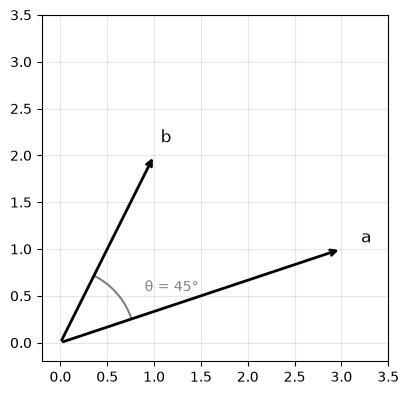

In [11]:
a, b = np.array([3.0, 1.0]), np.array([1.0, 2.0])
cos = cosine_similarity(a, b)
print(f"cos θ = {cos:.3f}  →  θ = arccos(cos θ) = {np.degrees(np.arccos(cos)):.1f}°")
print(f"vector_angle(a, b) = {vector_angle(a, b):.1f}°  (a mesma coisa)")
print(f"cosseno de a e 10·a = {cosine_similarity(a, 10 * a):.3f}")

fig, ax = plt.subplots(figsize=(4.5, 4.5))
for v, nome in ((a, "a"), (b, "b")):
    ax.annotate("", xy=v, xytext=(0, 0), arrowprops=dict(arrowstyle="->", lw=2))
    ax.text(*(v * 1.07), nome, fontsize=12)
arco = np.linspace(np.arctan2(a[1], a[0]), np.arctan2(b[1], b[0]), 30)
ax.plot(0.8 * np.cos(arco), 0.8 * np.sin(arco), color="gray")
ax.text(0.9, 0.55, f"θ = {vector_angle(a, b):.0f}°", color="gray")
ax.set_xlim(-0.2, 3.5); ax.set_ylim(-0.2, 3.5); ax.set_aspect("equal"); ax.grid(alpha=0.3);

### Cosseno × Jaccard na rede

O **Jaccard** (notebook 04, `similar_accounts(..., "jaccard_out")`) só olha **para quem** cada conta pagou: $|N(a) \cap N(b)| / |N(a) \cup N(b)|$. O **cosseno** olha também **quanto**. As laranjas de uma quadrilha repassam quase tudo o que recebem para o mesmo destino, então os vetores delas apontam na mesma direção, mesmo que os Pix de camuflagem tornem os conjuntos de parceiros diferentes.

In [12]:
fraudes = set(contas.loc[contas["is_fraud"], "account_id"])
laranjas = papel.index[papel == "laranja"]
acertos = {}
for metodo in ("jaccard_out", "cosine_out"):
    acertos[metodo] = np.mean([similar_accounts(G, l, method=metodo, top=5).index.isin(fraudes).mean()
                               for l in laranjas if G.out_degree(l)])
pd.Series(acertos, name="fração de fraudes entre as 5 contas mais parecidas com cada laranja").round(3)

jaccard_out    0.567
cosine_out     0.642
Name: fração de fraudes entre as 5 contas mais parecidas com cada laranja, dtype: float64

Aqui o cosseno encontra mais "irmãs" fraudulentas que o Jaccard, porque usa os valores. O script [`analisar_tipo_de_rede.py`](../scripts/analisar_tipo_de_rede.py) repete essa medida em vários cenários e sementes.

## Exercícios

1. **Ligação preferencial desligada.** Escreva um gerador "BA sem preferência": cada vértice novo se liga a $m = 3$ vértices antigos sorteados **uniformemente**. Compare a distribuição acumulada de graus com a do BA e o $\alpha$ estimado por `fit_power_law`.
2. **Transição de fase.** Para $n = 500$, $1000$ e $4000$, calcule a fração na componente gigante do Erdős–Rényi com $\langle k \rangle = 0{,}5$ e $\langle k \rangle = 1{,}5$. O que acontece com cada uma quando $n$ cresce?
3. **Cosseno à mão.** Calcule, sem o computador, o cosseno e o ângulo entre $a = (1, 1, 0)$ e $b = (0, 1, 1)$. Depois confira com `cosine_similarity` e `vector_angle`.
4. **Coletora que esvazia.** Gere o dataset com `collector_payouts=20` (a coletora repassa o dinheiro em ~20 Pix de saída; ver `configs/cenarios.yaml`, cenário `coletor_ativo`). O grau de saída das coletoras muda quanto? E a fração dos passeios que saem das vítimas e passam por elas?

In [13]:
# seu código aqui